# 01 · Data exploration: Olist

Goal: load the 7 tables, join them into **one row per order**, understand delays and reviews,
and estimate how many orders fit in each context size.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from rlm_logistics.data import load_tables, build_orders, serialize

t = load_tables()
pd.DataFrame({name: df.shape for name, df in t.items()}, index=["rows", "cols"]).T

,rows,cols
orders,99441,8
reviews,99224,7
items,112650,7
sellers,3095,4
customers,99441,5
products,32951,9
categories,71,2


## Join edge cases
* Some orders contain items from **several sellers**, so seller-level questions become ambiguous → we keep single-seller orders only.
* Some orders have **more than one review** → we keep the latest one.

In [2]:
multi_seller = (t["items"].groupby("order_id").seller_id.nunique() > 1).sum()
multi_review = (t["reviews"].order_id.value_counts() > 1).sum()
print(f"orders with >1 seller: {multi_seller:,}   orders with >1 review: {multi_review:,}")
t["orders"].order_status.value_counts()

orders with >1 seller: 1,278   orders with >1 review: 547


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [3]:
df = build_orders(t)
print(f"{len(df):,} delivered single-seller orders, {df.comment.notna().sum():,} with a comment")
df.head(3)

95,195 delivered single-seller orders, 38,078 with a comment


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,seller_id,category,...,seller_zip_code_prefix,seller_city,seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score,comment,days_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,3504c0cb71d7fa48d967e0e4c94d59d9,housewares,...,9350,maua,SP,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.0,"Não testei o produto ainda, mas ele veio corre...",-8
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,289cdb325fb7e7f891c38608bf9e0962,perfumery,...,31570,belo horizonte,SP,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.0,Muito bom o produto.,-6
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,4869f7a5dfa277a7dca6462dcf3b52b2,auto,...,14840,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.0,NaN,-18


## Delays
`days_late` = delivered date − estimated date. Positive = late, negative = early.

late orders: 6.9%


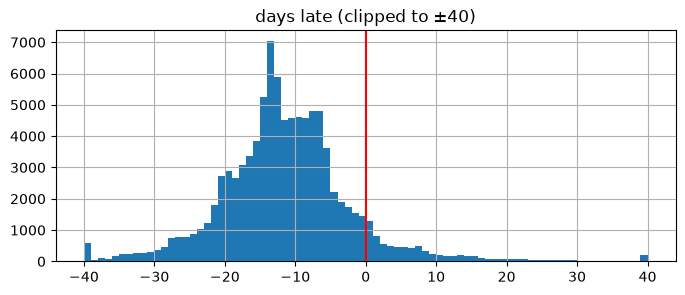

In [4]:
df["late"] = df.days_late > 0
print(f"late orders: {df.late.mean():.1%}")
df.days_late.clip(-40, 40).hist(bins=80, figsize=(8, 3))
plt.axvline(0, color="red"); plt.title("days late (clipped to ±40)"); plt.show()

## Do late orders get worse reviews?
If delivery matters, the average score should drop for late orders. This is the signal our T2 questions build on.

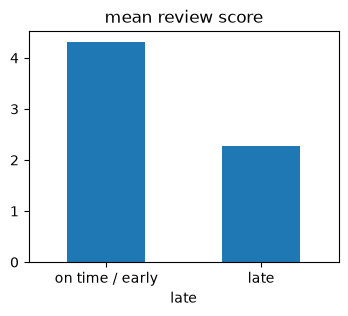

review_score,1.0,2.0,3.0,4.0,5.0
late,,,,,
False,0.06,0.03,0.08,0.21,0.63
True,0.54,0.09,0.11,0.10,0.17


In [5]:
ax = df.groupby("late").review_score.mean().plot.bar(figsize=(4, 3), title="mean review score")
ax.set_xticklabels(["on time / early", "late"], rotation=0); plt.show()
pd.crosstab(df.late, df.review_score, normalize="index").round(2)

## Comments: the semantic core
Only orders with a comment go into the text contexts. Reviews are in Portuguese.

In [6]:
c = df[df.comment.notna()]
print(f"comment coverage: {len(c) / len(df):.1%}")
for r in c.sample(5, random_state=42).itertuples():
    print(f"{r.review_score:.0f}/5 late={r.late}: {r.comment[:120]}")

comment coverage: 40.0%
3/5 late=False: Satisfeito
1/5 late=True: Alem do prazo de entrega bem extenso a mercadoria ainda encontra-se retida, sem atualização, completando hoje exatamente
5/5 late=False: otimo
1/5 late=False: Comprei um produto e recebi outro. A targaryen não apresenta solução para o problema. Precisei fazer reclamação no site 
5/5 late=False: Produto bom. Entrega antes do prazo


## Where are sellers and customers?

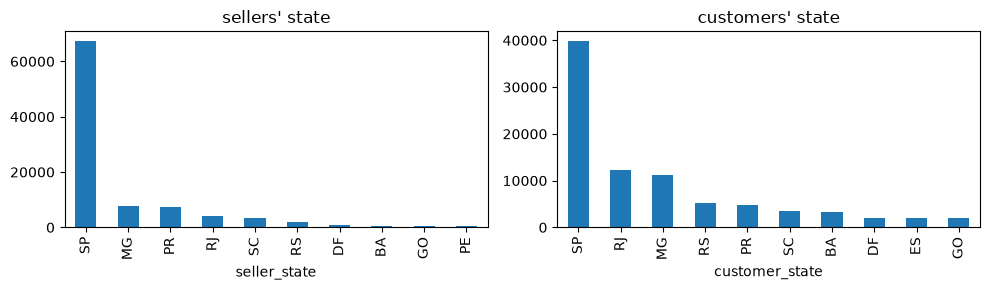

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
df.seller_state.value_counts().head(10).plot.bar(ax=axes[0], title="sellers' state")
df.customer_state.value_counts().head(10).plot.bar(ax=axes[1], title="customers' state")
plt.tight_layout(); plt.show()

## Serialized records and context sizes
Each order becomes one line of text. Rough rule: **1 token ≈ 4 characters** (Phase 2 measures exactly with a real tokenizer).

In [8]:
lines = c.apply(serialize, axis=1)
print(lines.iloc[0], "\n")
tokens_per_record = lines.str.len().mean() / 4
print(f"≈{tokens_per_record:.0f} tokens per record")
for size in [32_000, 128_000, 512_000, 2_000_000]:
    print(f"{size:>9,} tokens ≈ {size / tokens_per_record:>7,.0f} records")
print(f"all {len(lines):,} commented orders ≈ {len(lines) * tokens_per_record:,.0f} tokens")

[order e481f51cbdc54678b7cc49136f2d6af7] seller=3504c0cb71d7fa48d967e0e4c94d59d9 (SP/maua) customer=SP/sao paulo category=housewares purchased=2017-10-02 estimated=2017-10-18 delivered=2017-10-10 (8 days early) review=4/5 "Não testei o produto ainda, mas ele veio correto e em boas condições. Apenas a caixa que veio bem amassada e danificada, o que ficará chato, pois se trata de um presente." 

≈75 tokens per record
   32,000 tokens ≈     425 records
  128,000 tokens ≈   1,700 records
  512,000 tokens ≈   6,799 records
2,000,000 tokens ≈  26,560 records
all 38,078 commented orders ≈ 2,867,340 tokens


## Takeaways
* ~95K usable orders; ~40% have a comment, and those are what go into the contexts. Only ~7% of orders are late.
* Late deliveries clearly drag review scores down, so delivery-vs-product complaints is a meaningful question.
* All commented orders together are ≈2.9M tokens, so the 2M context uses ~70% of them; the data is big enough for every size.
* A 32K context holds only a few hundred orders. Even that is far more than RAG's top‑k.